In [ ]:
from google.colab import files

uploaded = files.upload()

Saving titanic.csv to titanic.csv


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn. metrics import mean_absolute_error, mean_squared_error,r2_score, accuracy_score
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import BernoulliNB
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import seaborn as sns


In [ ]:
df=pd.read_csv('titanic.csv', encoding='latin1')
print(df)
print("Columns names=",df.columns)
print("Data types=",df.dtypes)

     PassengerId  Pclass                                          Name  \
0            892       3                              Kelly, Mr. James   
1            893       3              Wilkes, Mrs. James (Ellen Needs)   
2            894       2                     Myles, Mr. Thomas Francis   
3            895       3                              Wirz, Mr. Albert   
4            896       3  Hirvonen, Mrs. Alexander (Helga E Lindqvist)   
..           ...     ...                                           ...   
413         1305       3                            Spector, Mr. Woolf   
414         1306       1                  Oliva y Ocana, Dona. Fermina   
415         1307       3                  Saether, Mr. Simon Sivertsen   
416         1308       3                           Ware, Mr. Frederick   
417         1309       3                      Peter, Master. Michael J   

        Sex   Age  SibSp  Parch              Ticket      Fare Cabin Embarked  \
0      male  34.5      0      0

In [ ]:
df.columns=df.columns.str.replace(' ','_')
print("replacing spaces:", df.columns)
df.columns = df.columns.str.lower()
print(" lowercase:", df.columns)

replacing spaces: Index(['PassengerId', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch',
       'Ticket', 'Fare', 'Cabin', 'Embarked', 'Survived'],
      dtype='object')
 lowercase: Index(['passengerid', 'pclass', 'name', 'sex', 'age', 'sibsp', 'parch',
       'ticket', 'fare', 'cabin', 'embarked', 'survived'],
      dtype='object')


In [ ]:
print("Count Duplicates=",df.duplicated().sum())

df=df.drop_duplicates()


Count Duplicates= 0


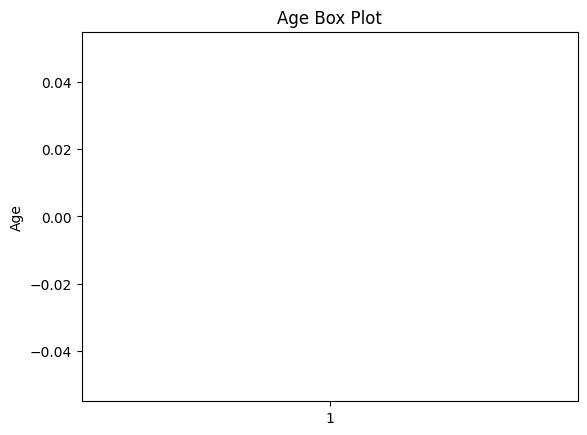

In [ ]:
#Age box plot
plt.boxplot(
    df["age"],
    vert=True,
    patch_artist=True,
    boxprops=dict(facecolor="pink")
)

plt.title("Age Box Plot")
plt.ylabel("Age")
plt.show()

In [ ]:
outlier_columns=['age']

for col in outlier_columns:


  df_temp = df.dropna(subset=[col])

  Q1=df_temp[col].quantile(0.25)
  Q3=df_temp[col].quantile(0.75)
  IQR=Q3-Q1
  lower_bound=Q1-1.5*IQR
  upper_bound=Q3+1.5*IQR

  print(col)
  print("Lower bound=",lower_bound)
  print("Upper bound=",upper_bound)

  df=df[df[col]>=lower_bound]
  df=df[df[col]<=upper_bound]


print(df)

age
Lower bound= -6.0
Upper bound= 66.0
     passengerid  pclass                                             name  \
0            892       3                                 Kelly, Mr. James   
1            893       3                 Wilkes, Mrs. James (Ellen Needs)   
2            894       2                        Myles, Mr. Thomas Francis   
3            895       3                                 Wirz, Mr. Albert   
4            896       3     Hirvonen, Mrs. Alexander (Helga E Lindqvist)   
..           ...     ...                                              ...   
409         1301       3                        Peacock, Miss. Treasteall   
411         1303       1  Minahan, Mrs. William Edward (Lillian E Thorpe)   
412         1304       3                   Henriksson, Miss. Jenny Lovisa   
414         1306       1                     Oliva y Ocana, Dona. Fermina   
415         1307       3                     Saether, Mr. Simon Sivertsen   

        sex   age  sibsp  parch    

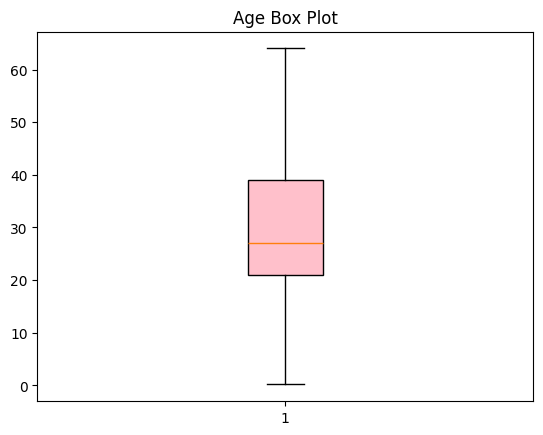

In [ ]:
# Age box plot
plt.boxplot(df["age"],vert=True,patch_artist=True,boxprops=dict(facecolor='Pink'))
plt.title("Age Box Plot")
plt.show()

In [ ]:
X = df["sex"].apply(lambda x: 1 if x == "male" else 0)
Y = df["survived"]

X = X.to_frame()

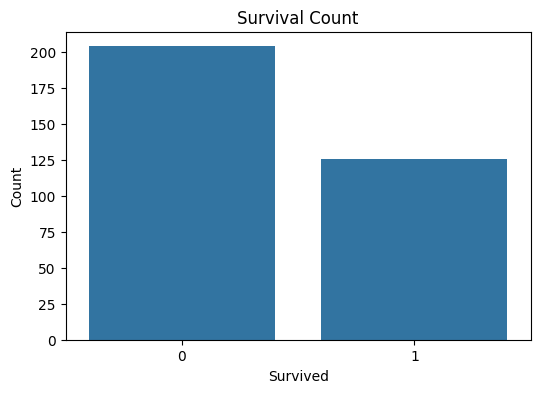

In [ ]:
plt.figure(figsize=(6,4))
sns.countplot(x="survived", data=df)
plt.title("Survival Count")
plt.xlabel("Survived")
plt.ylabel("Count")
plt.show()

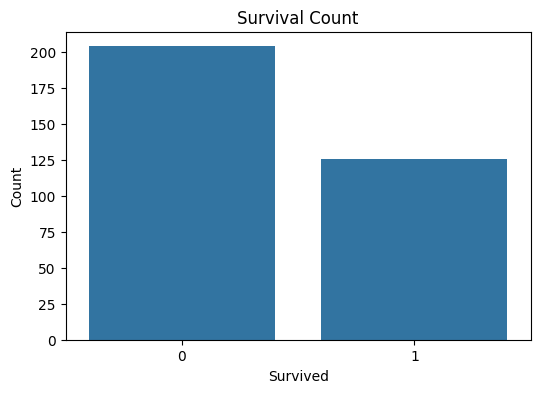

In [ ]:
plt.figure(figsize=(6,4))
sns.countplot(x="survived", data=df)
plt.title("Survival Count")
plt.xlabel("Survived")
plt.ylabel("Count")
plt.show()

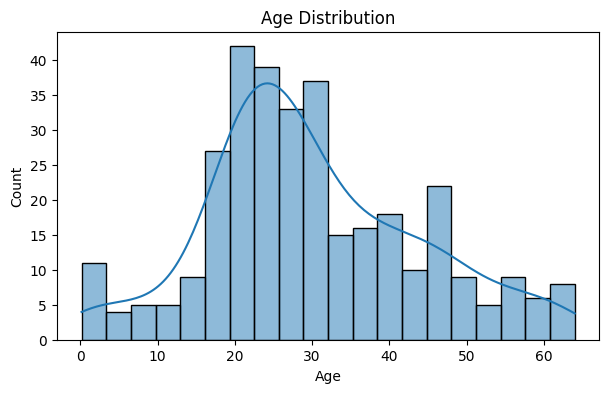

In [ ]:
plt.figure(figsize=(7,4))
sns.histplot(df["age"].dropna(), bins=20, kde=True)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Count")
plt.show()

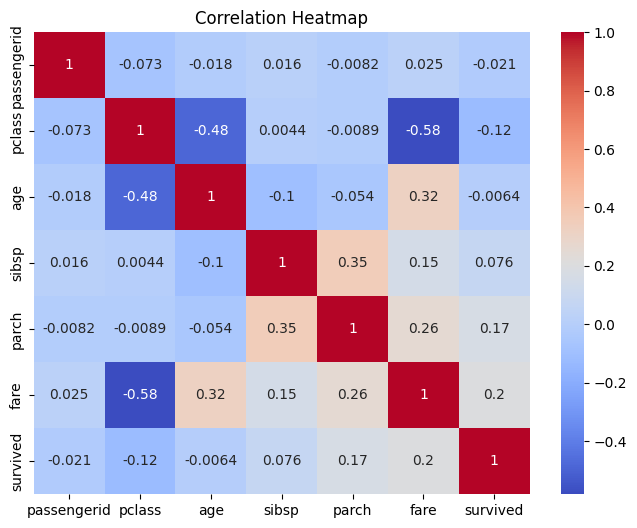

In [ ]:
plt.figure(figsize=(8,6))
sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm"
)
plt.title("Correlation Heatmap")
plt.show()

In [ ]:
X = df[["sex", "age", "sibsp", "parch", "fare"]]
y = df["survived"]
# Missing values
X["age"] = X["age"].fillna(X["age"].median())
print(X["age"])

0      34.5
1      47.0
2      62.0
3      27.0
4      22.0
       ... 
409     3.0
411    37.0
412    28.0
414    39.0
415    38.5
Name: age, Length: 330, dtype: float64


/tmp/ipykernel_558/2014046349.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X["age"] = X["age"].fillna(X["age"].median())


In [ ]:
# Encoding Sex
X["sex"] = X["sex"].map({
    "male": 0,
    "female": 1
})
print(X.isnull().sum())

sex      0
age      0
sibsp    0
parch    0
fare     1
dtype: int64


/tmp/ipykernel_558/376497607.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X["sex"] = X["sex"].map({


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    Y,
    test_size=0.2,
    random_state=42,
    stratify=Y
)

print("\nTraining Data:", X_train.shape)
print("Testing Data:", X_test.shape)


Training Data: (264, 5)
Testing Data: (66, 5)


In [ ]:
X_train['sex'] = X_train['sex'].fillna(0)
X_test['sex'] = X_test['sex'].fillna(0)

# Fill any remaining NaN values in X_train and X_test (specifically the 'fare' column)
fare_median = X_train['fare'].median()
X_train['fare'] = X_train['fare'].fillna(fare_median)
X_test['fare'] = X_test['fare'].fillna(fare_median)

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(y_pred)

[1 0 1 0 0 0 1 0 0 1 0 0 0 1 0 1 1 0 1 0 0 1 0 1 0 0 1 0 0 0 0 1 0 0 1 1 0
 0 1 0 0 0 0 0 0 0 1 0 0 1 0 1 0 0 0 0 1 1 1 1 1 0 1 0 0 1]


In [ ]:
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[41  0]
 [ 0 25]]


In [ ]:
# Prepare X_processed to resolve the NameError
X_processed = X.copy()
X_processed['fare'] = X_processed['fare'].fillna(X_processed['fare'].median())

# Create samples as Pandas DataFrames with proper feature names to avoid UserWarning
female_sample = pd.DataFrame([[
    1,
    X_processed['age'].median(),
    X_processed['sibsp'].median(),
    X_processed['parch'].median(),
    X_processed['fare'].median()
]], columns=X_processed.columns)

male_sample = pd.DataFrame([[
    0,
    X_processed['age'].median(),
    X_processed['sibsp'].median(),
    X_processed['parch'].median(),
    X_processed['fare'].median()
]], columns=X_processed.columns)

probfemale = model.predict_proba(female_sample)
print("Probability for Female:", probfemale)

probMale = model.predict_proba(male_sample)
print("Probability for Male:", probMale)

Probability for Female: [[0.01339755 0.98660245]]
Probability for Male: [[0.99717946 0.00282054]]


In [ ]:
model = BernoulliNB()

X_processed = X.copy()
# X['sex'] has already been mapped to 0/1, so we do not need to map it again.
# Instead, we just ensure there are no NaNs left in any columns
X_processed['age'] = X_processed['age'].fillna(X_processed['age'].median())
X_processed['fare'] = X_processed['fare'].fillna(X_processed['fare'].median())

model.fit(X_processed, Y)
print("Model training score:", model.score(X_processed, Y))

Model training score: 1.0


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

X_test_processed = X_test.copy()

if 'age' not in X_test_processed.columns:
    X_test_processed['age'] = X_processed['age'].median()
else:
    X_test_processed['age'] = X_test_processed['age'].fillna(X_processed['age'].median())

if 'sibsp' not in X_test_processed.columns:
    X_test_processed['sibsp'] = X_processed['sibsp'].median()
else:
    X_test_processed['sibsp'] = X_test_processed['sibsp'].fillna(X_processed['sibsp'].median())

if 'parch' not in X_test_processed.columns:
    X_test_processed['parch'] = X_processed['parch'].median()
else:
    X_test_processed['parch'] = X_test_processed['parch'].fillna(X_processed['parch'].median())

if 'fare' not in X_test_processed.columns:
    X_test_processed['fare'] = X_processed['fare'].median()
else:
    X_test_processed['fare'] = X_test_processed['fare'].fillna(X_processed['fare'].median())

y_pred = model.predict(X_test_processed)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
print("Accuracy  :", round(accuracy, 4))
print("Precision :", round(precision, 4))
print("Recall    :", round(recall, 4))
print("F1 Score  :", round(f1, 4))

Accuracy  : 1.0
Precision : 1.0
Recall    : 1.0
F1 Score  : 1.0


In [ ]:
X_for_prediction = X.copy()

# We remove the .map() step because the 'sex' column is already mapped to 0 and 1 in X.

X_for_prediction['fare'] = X_for_prediction['fare'].fillna(X_for_prediction['fare'].median())

X_for_prediction['age'] = X_for_prediction['age'].fillna(X_processed['age'].median())
X_for_prediction['sibsp'] = X_for_prediction['sibsp'].fillna(X_processed['sibsp'].median())
X_for_prediction['parch'] = X_for_prediction['parch'].fillna(X_processed['parch'].median())

y_pred = model.predict(X_for_prediction)
print(classification_report(Y, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       204
           1       1.00      1.00      1.00       126

    accuracy                           1.00       330
   macro avg       1.00      1.00      1.00       330
weighted avg       1.00      1.00      1.00       330



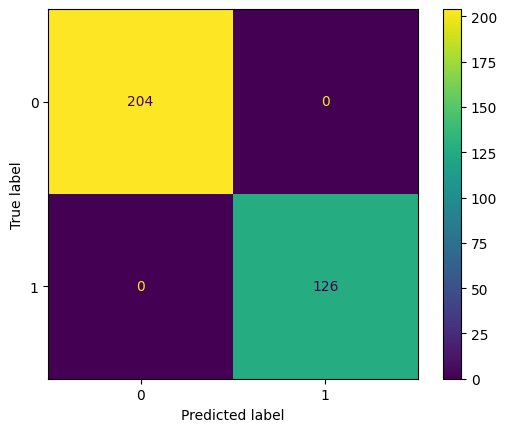

In [ ]:

cm = confusion_matrix(Y, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
# Display confusion matrix
disp.plot()

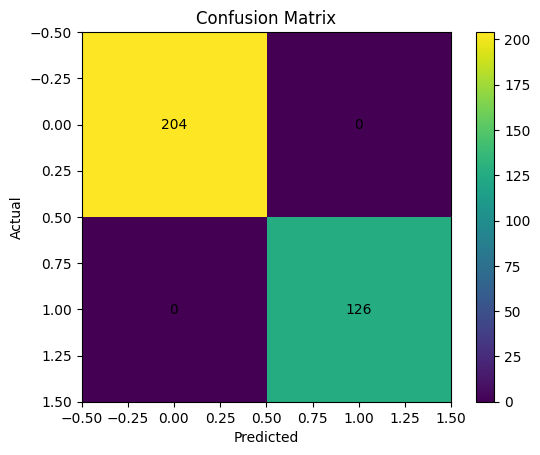

In [ ]:
import matplotlib.pyplot as plt

cm = confusion_matrix(Y, y_pred)

plt.imshow(cm)

plt.colorbar()

plt.title("Confusion Matrix")

plt.xlabel("Predicted")
plt.ylabel("Actual")

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, cm[i, j],
                 ha="center",
                 va="center")

plt.show()